<a href="https://colab.research.google.com/github/mansiguptacs/CMPE_258_TrafficForecastingUsing_GraphNN/blob/main/notebooks/04_initial_data_exploration.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# METR-LA Traffic-Speed Data Exploration

This notebook explores the METR-LA traffic-speed dataset used for traffic forecasting with graph neural networks.

In [1]:
from google.colab import drive

drive.flush_and_unmount()
drive.mount("/content/drive")

Mounted at /content/drive


In [2]:
import os
import pandas as pd

DATA_PATH = "/content/drive/MyDrive/metr-la.h5"

print(os.path.exists(DATA_PATH))

True


In [3]:
traffic_df = pd.read_hdf(DATA_PATH)

print("Shape:", traffic_df.shape)
print("Start:", traffic_df.index.min())
print("End:", traffic_df.index.max())

traffic_df.head()

Shape: (34272, 207)
Start: 2012-03-01 00:00:00
End: 2012-06-27 23:55:00


,773869,767541,767542,717447,717446,717445,773062,767620,737529,717816,...,772167,769372,774204,769806,717590,717592,717595,772168,718141,769373
2012-03-01 00:00:00,64.375000,67.625000,67.125000,61.500000,66.875000,68.750000,65.125,67.125,59.625000,62.750000,...,45.625000,65.500,64.500000,66.428571,66.875,59.375000,69.000000,59.250000,69.000000,61.875
2012-03-01 00:05:00,62.666667,68.555556,65.444444,62.444444,64.444444,68.111111,65.000,65.000,57.444444,63.333333,...,50.666667,69.875,66.666667,58.555556,62.000,61.111111,64.444444,55.888889,68.444444,62.875
2012-03-01 00:10:00,64.000000,63.750000,60.000000,59.000000,66.500000,66.250000,64.500,64.250,63.875000,65.375000,...,44.125000,69.000,56.500000,59.250000,68.125,62.500000,65.625000,61.375000,69.857143,62.000
2012-03-01 00:15:00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000,0.000,0.000000,0.000000,...,0.000000,0.000,0.000000,0.000000,0.000,0.000000,0.000000,0.000000,0.000000,0.000
2012-03-01 00:20:00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000,0.000,0.000000,0.000000,...,0.000000,0.000,0.000000,0.000000,0.000,0.000000,0.000000,0.000000,0.000000,0.000


## 1. Dataset Overview

In [4]:
print("Rows (time points):", traffic_df.shape[0])
print("Sensors:", traffic_df.shape[1])
print("Data types:")
print(traffic_df.dtypes.value_counts())


Rows (time points): 34272
Sensors: 207
Data types:
float64    207
Name: count, dtype: int64


## 2. Time Range and Sampling Interval

In [5]:
print("First timestamp:", traffic_df.index.min())
print("Last timestamp:", traffic_df.index.max())
print("Number of timestamps:", len(traffic_df))

time_differences = traffic_df.index.to_series().diff()

print("\nMost common time intervals:")
print(time_differences.value_counts().head())

First timestamp: 2012-03-01 00:00:00
Last timestamp: 2012-06-27 23:55:00
Number of timestamps: 34272

Most common time intervals:
0 days 00:05:00    34271
Name: count, dtype: int64


## 3. Missing-Value Analysis

In [6]:
missing_values = traffic_df.isna().sum().sum()
total_values = traffic_df.size
missing_percentage = 100 * missing_values / total_values

print("Total values:", total_values)
print("Missing values:", missing_values)
print("Missing percentage:", round(missing_percentage, 2), "%")

Total values: 7094304
Missing values: 0
Missing percentage: 0.0 %


## 4. Descriptive Statistics

In [7]:
summary_statistics = traffic_df.describe()

summary_statistics

,773869,767541,767542,717447,717446,717445,773062,767620,737529,717816,...,772167,769372,774204,769806,717590,717592,717595,772168,718141,769373
count,34272.000000,34272.000000,34272.000000,34272.000000,34272.000000,34272.000000,34272.000000,34272.000000,34272.000000,34272.000000,...,34272.000000,34272.000000,34272.000000,34272.000000,34272.000000,34272.000000,34272.000000,34272.000000,34272.000000,34272.000000
mean,54.631359,60.452789,60.726120,49.524287,46.079798,50.952003,54.471684,57.255095,56.068044,52.871841,...,37.803342,58.156679,51.217523,59.795754,59.329923,56.915083,62.484679,54.697381,58.920210,51.197504
std,22.619199,15.970239,18.313353,15.843261,19.350345,16.681760,17.984761,18.751065,18.240361,23.343805,...,13.525743,20.690411,22.224997,16.126225,19.849950,18.260438,16.959238,16.303651,19.080474,21.239354
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,60.364583,63.000000,65.444444,50.333333,34.666667,49.555556,55.750000,61.000000,58.222222,43.428571,...,30.444444,64.111111,53.444444,61.714286,63.666667,60.222222,65.888889,50.125000,62.888889,54.125000
50%,64.888889,65.000000,67.375000,53.875000,46.000000,56.111111,62.111111,63.333333,62.444444,65.875000,...,43.222222,67.111111,61.777778,64.875000,66.777778,63.000000,67.625000,61.125000,66.125000,62.000000
75%,66.875000,66.375000,68.444444,58.125000,64.500000,60.333333,65.000000,65.000000,64.888889,67.625000,...,46.625000,68.444444,64.375000,66.500000,68.250000,64.750000,68.625000,64.444444,67.750000,63.444444
max,70.000000,70.000000,70.000000,70.000000,70.000000,70.000000,70.000000,70.000000,70.000000,70.000000,...,65.000000,70.000000,70.000000,70.000000,70.000000,70.000000,70.000000,70.000000,70.000000,70.000000


In [8]:
print("Overall average speed:", traffic_df.mean().mean())
print("Minimum speed:", traffic_df.min().min())
print("Maximum speed:", traffic_df.max().max())

Overall average speed: 53.7190211024135
Minimum speed: 0.0
Maximum speed: 70.0


## 5. Traffic-Speed Visualizations

### 5.1 Traffic Speed Over the Complete Observation Period

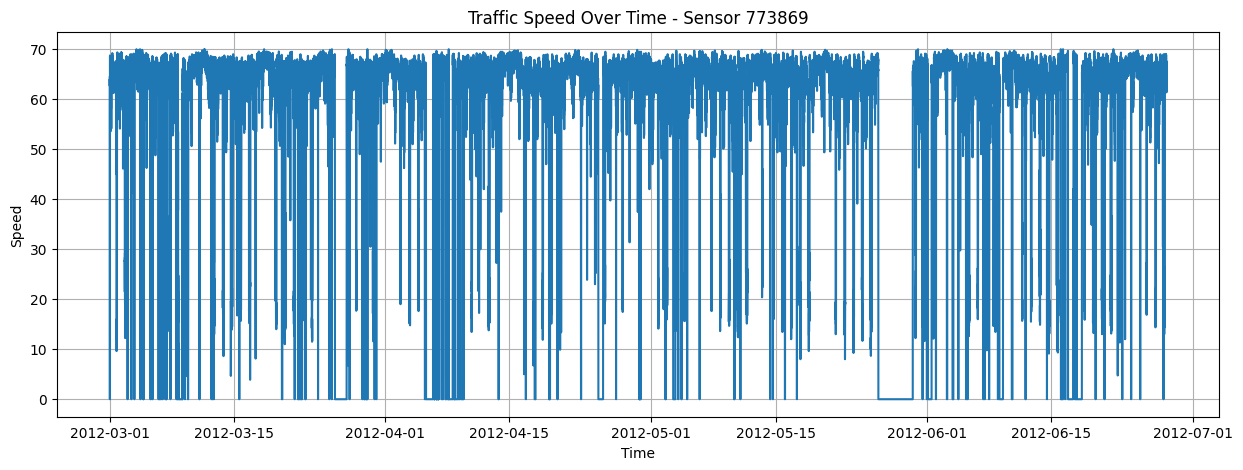

In [9]:
import matplotlib.pyplot as plt

sensor_id = traffic_df.columns[0]

plt.figure(figsize=(15, 5))
plt.plot(traffic_df.index, traffic_df[sensor_id])

plt.title(f"Traffic Speed Over Time - Sensor {sensor_id}")
plt.xlabel("Time")
plt.ylabel("Speed")
plt.grid(True)
plt.show()

### 5.2 Traffic Speed During the First 24 Hours

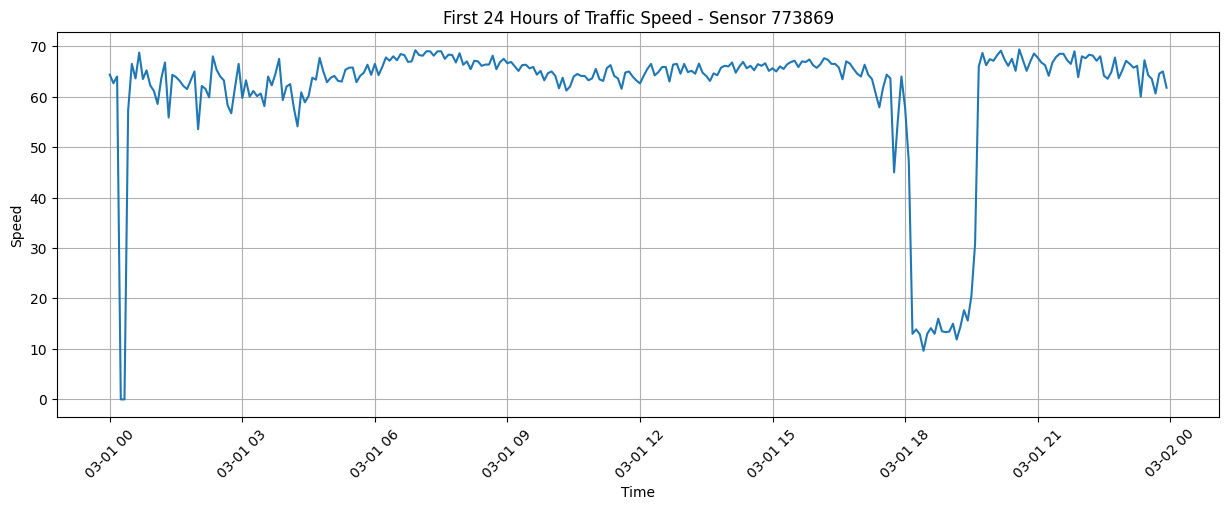

In [10]:
one_day = traffic_df.iloc[:288]

plt.figure(figsize=(15, 5))
plt.plot(one_day.index, one_day[sensor_id])

plt.title(f"First 24 Hours of Traffic Speed - Sensor {sensor_id}")
plt.xlabel("Time")
plt.ylabel("Speed")
plt.xticks(rotation=45)
plt.grid(True)
plt.show()

### 5.3 Comparison Across Five Sensors

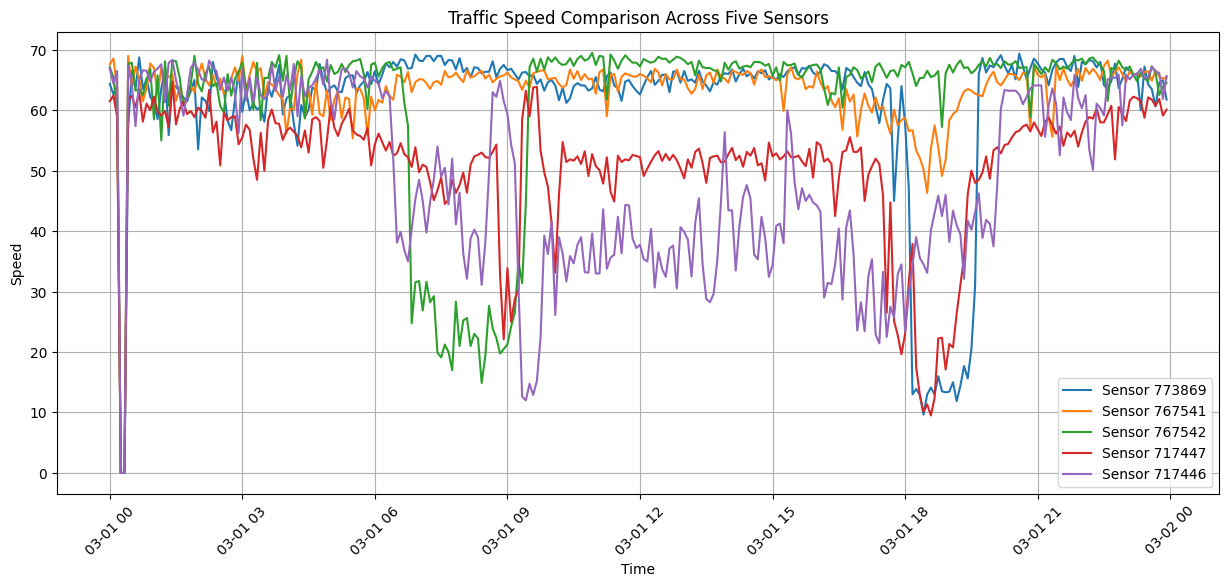

In [11]:
plt.figure(figsize=(15, 6))

for sensor in traffic_df.columns[:5]:
    plt.plot(
        traffic_df.index[:288],
        traffic_df[sensor].iloc[:288],
        label=f"Sensor {sensor}"
    )

plt.title("Traffic Speed Comparison Across Five Sensors")
plt.xlabel("Time")
plt.ylabel("Speed")
plt.xticks(rotation=45)
plt.legend()
plt.grid(True)
plt.show()

## 6. Sensor-Correlation Analysis

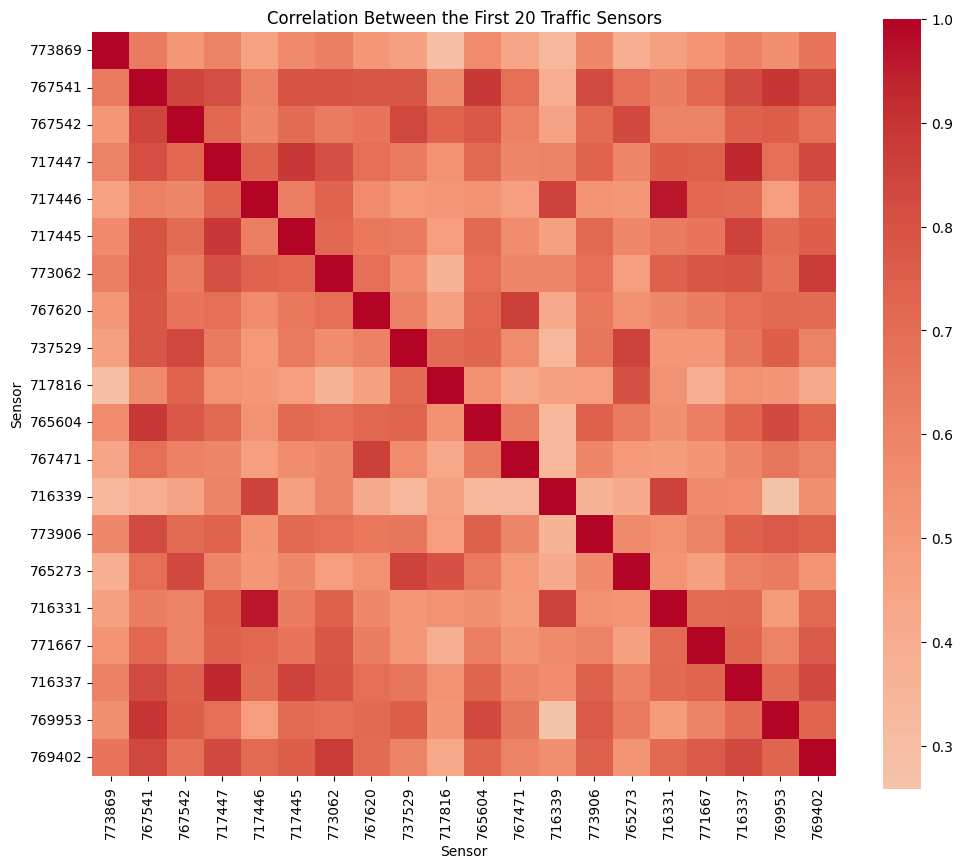

In [12]:
import seaborn as sns

correlation_matrix = traffic_df.corr()

plt.figure(figsize=(12, 10))

sns.heatmap(
    correlation_matrix.iloc[:20, :20],
    cmap="coolwarm",
    center=0,
    square=True
)

plt.title("Correlation Between the First 20 Traffic Sensors")
plt.xlabel("Sensor")
plt.ylabel("Sensor")
plt.show()

## 7. Save Correlation Results

In [13]:
correlation_matrix.to_csv("metr_la_sensor_correlations.csv")

print("Correlation matrix saved successfully.")

Correlation matrix saved successfully.


## 8. Initial Exploration Summary

The METR-LA dataset contains 34,272 time points collected from 207 traffic sensors at five-minute intervals. The dataset contains no NaN values. The time-series plots show that traffic speeds vary over time and that multiple sensors exhibit similar patterns. The correlation heatmap indicates relationships between sensor measurements, which can support the construction of a correlation-based graph for traffic forecasting.